<a href="https://colab.research.google.com/github/Saaraa-vanam/KITE_FDP-Upskilling/blob/main/05_Logistic_Regression_Confusion_Matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

# Automatically grab the uploaded filename
file_name = list(uploaded.keys())[0]
print(f"Loaded file: {file_name}")

Saving Logistic_Regression_FDP_Student_Dataset_130_Samples.xlsx to Logistic_Regression_FDP_Student_Dataset_130_Samples.xlsx
Loaded file: Logistic_Regression_FDP_Student_Dataset_130_Samples.xlsx


Confusion Matrix:
 [[25  1]
 [ 2 11]]

Classification Report:
               precision    recall  f1-score   support

        FAIL       0.92      0.85      0.88        13
        PASS       0.93      0.96      0.94        26

    accuracy                           0.92        39
   macro avg       0.92      0.90      0.91        39
weighted avg       0.92      0.92      0.92        39



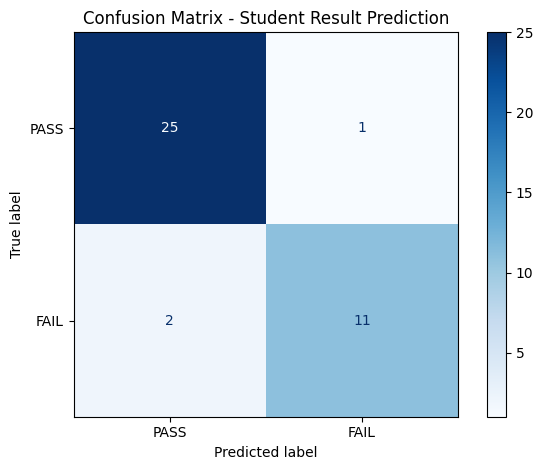

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1. Read the 'Student_Data' sheet
df = pd.read_excel("Logistic_Regression_FDP_Student_Dataset_130_Samples.xlsx", sheet_name='Student_Data')

# 2. Define features (X) and target (y)
# Exclude 'Student_ID' (identifier) and 'Exam_Marks' (to prevent data leakage since Result is derived from Exam_Marks >= 50)
X = df[['Study_Hours', 'Attendance_Percent', 'Previous_Marks', 'Assignment_Score']]
y = df['Result']

# 3. Split into training (70%) and testing (30%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 4. Train Logistic Regression classifier
model = LogisticRegression()
model.fit(X_train, y_train)

# 5. Predict on the test set
y_pred = model.predict(X_test)

# 6. Compute and display Confusion Matrix & Classification Report
labels = ['PASS', 'FAIL']
cm = confusion_matrix(y_test, y_pred, labels=labels)

print("Confusion Matrix:\n", cm)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 7. Plot the Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Student Result Prediction')
plt.tight_layout()
plt.show()